In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rahulogoel/isot-fake-news-dataset/News_Dataset/True.csv
/kaggle/input/datasets/rahulogoel/isot-fake-news-dataset/News_Dataset/Fake.csv


# Importing Libraries

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import json
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report , confusion_matrix
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Bidirectional , LSTM ,Dense , Dropout
from tensorflow.keras.callbacks import EarlyStopping , ReduceLROnPlateau , ModelCheckpoint


# Inspecting the Data

In [3]:
# Fake dataset
df=pd.read_csv("/kaggle/input/datasets/rahulogoel/isot-fake-news-dataset/News_Dataset/Fake.csv")

In [4]:
df.head()


,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [5]:
df['subject'].value_counts()

subject
News               9050
politics           6841
left-news          4459
Government News    1570
US_News             783
Middle-east         778
Name: count, dtype: int64

In [6]:
# Real dataset
df2=pd.read_csv("/kaggle/input/datasets/rahulogoel/isot-fake-news-dataset/News_Dataset/True.csv")

In [7]:
df2.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [8]:
df2['subject'].value_counts()

subject
politicsNews    11272
worldnews       10145
Name: count, dtype: int64

# Creating new columns for Fake and real news

In [9]:
# Fake ->0 ,Real ->1
df['label']= 0
df2['label']=1

In [10]:
df.drop('date', axis=1 , inplace=True)

In [11]:
df.head(2)

,title,text,subject,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,0


In [12]:
df2.drop('date', axis=1 , inplace =True)

In [13]:
df2.head(2)

,title,text,subject,label
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,1
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,1


# Merging the Datasets

In [14]:
df=pd.concat([df ,df2] , ignore_index=True)

In [15]:
df.nunique()

title      38729
text       38646
subject        8
label          2
dtype: int64

In [16]:
df[['title', 'label']].sample(10, random_state=1)

,title,label
4528,Trump Calls For This Racist Policy To Be Forc...,0
31727,Republican ex-defense secretary Cohen backs Hi...,1
10937,"TEACHER QUITS JOB After 5th, 6th Grade Muslim ...",0
13470,LAURA INGRAHAM RIPS INTO THE PRESS…Crowd Goes ...,0
40814,Germany's Merkel suffers state vote setback as...,1
12702,WHOA! MELANIA TRUMP BREAKS HER SILENCE…Fires B...,0
2736,Study Shows Democrats Are Better Drivers For ...,0
31730,U.S. lawmakers want moratorium on commercial f...,1
42479,The new risk for Europe: an inward-looking Ger...,1
26780,"Trump still standing, but damaged by Comey's t...",1


In [17]:
df.isnull().sum()

title      0
text       0
subject    0
label      0
dtype: int64

# Dropping duplicate values

In [18]:
df.duplicated().sum()

np.int64(213)

In [19]:
df.dropna(inplace=True)

In [20]:
df.drop_duplicates(inplace=True)

In [21]:
df=df.reset_index(drop=True)

In [22]:
df.duplicated().sum()

np.int64(0)

In [23]:
df.isnull().sum()

title      0
text       0
subject    0
label      0
dtype: int64

In [24]:
df.head()

,title,text,subject,label
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,0
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,0
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,0
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,0
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,0


# Target variable distribution 

In [25]:
df['label'].value_counts()
# 0-> fake and 1-> Real

label
0    23477
1    21208
Name: count, dtype: int64

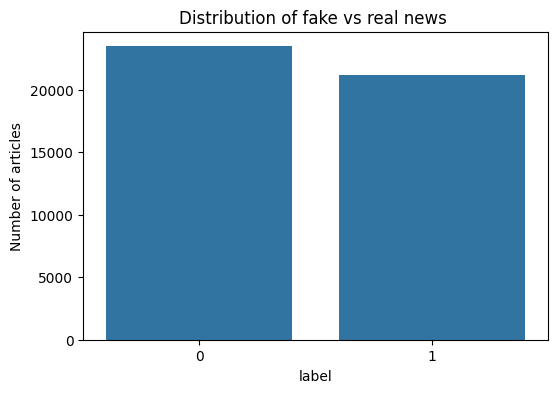

In [26]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    x='label'
)

plt.title("Distribution of fake vs real news ")
plt.xlabel("label")
plt.ylabel("Number of articles")
plt.show()

# Subject Distribution

In [27]:
df.columns

Index(['title', 'text', 'subject', 'label'], dtype='object')

In [28]:
df['subject'].value_counts()

subject
politicsNews       11217
worldnews           9991
News                9050
politics            6838
left-news           4458
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64

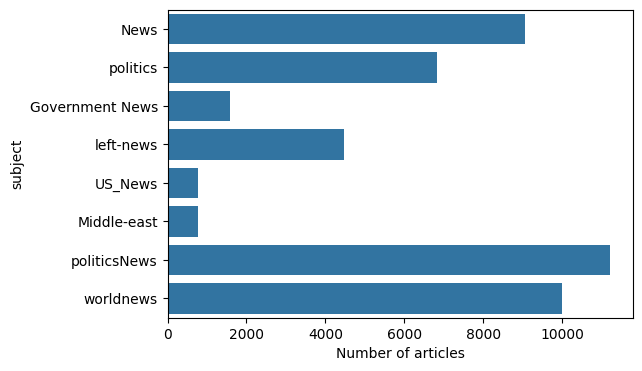

In [29]:
plt.figure(figsize=(6,4))

sns.countplot(
    data=df,
    y='subject'
)
plt.xlabel('Number of articles')
plt.show()

# Subject vs label

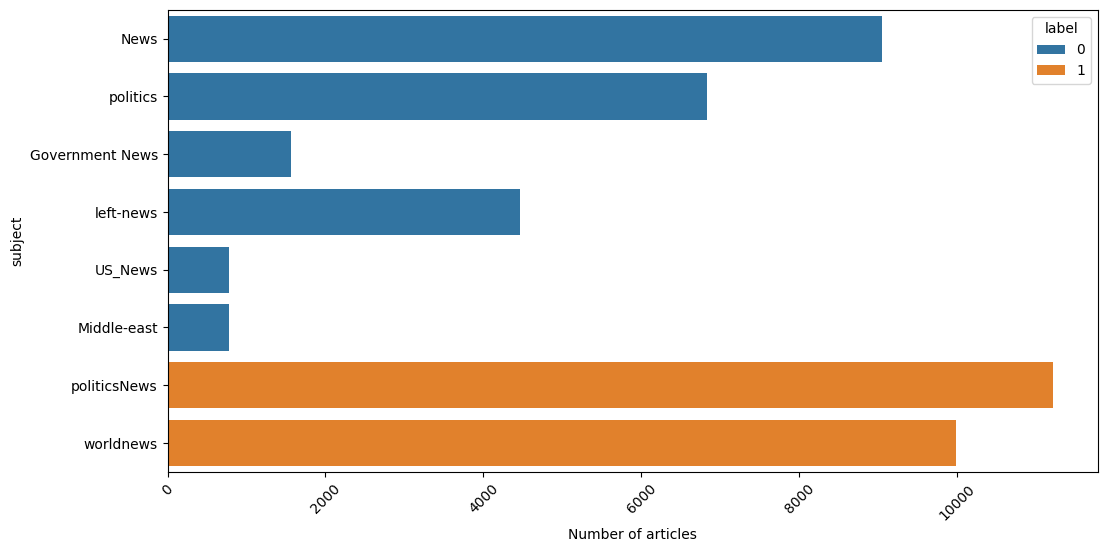

In [30]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    y='subject',
    hue='label'
)
plt.xlabel('Number of articles')
plt.xticks(rotation=45)

plt.show()

# Word count analysis

In [31]:
max(df['text'].str.split().str.len())


8135

In [32]:
min(df['text'].str.split().str.len())


0

In [33]:
df["word_count"] = df["text"].str.split().str.len()

In [34]:
df['word_count'].describe()

count    44685.000000
mean       404.944836
std        351.564647
min          0.000000
25%        203.000000
50%        362.000000
75%        512.000000
max       8135.000000
Name: word_count, dtype: float64

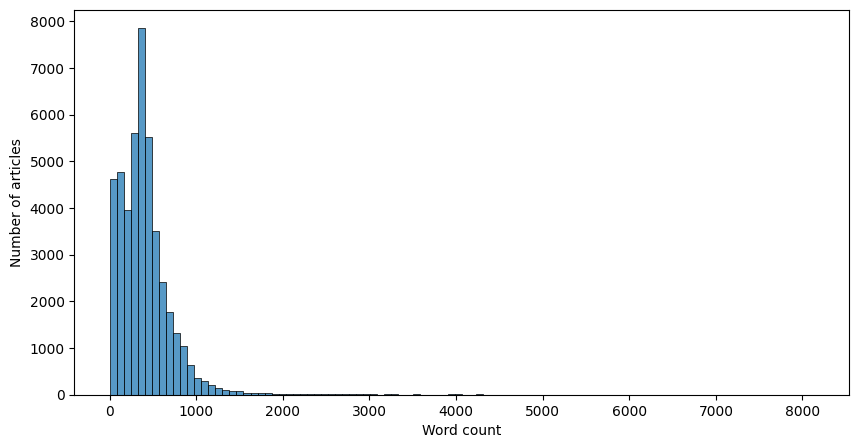

In [35]:
# Plot to show the variation in text length

plt.figure(figsize=(10,5))

sns.histplot(
    data=df,
    x='word_count',
    bins=100
)
plt.xlabel('Word count')
plt.ylabel('Number of articles')
plt.show()

In [36]:
df['label'].unique()

array([0, 1])

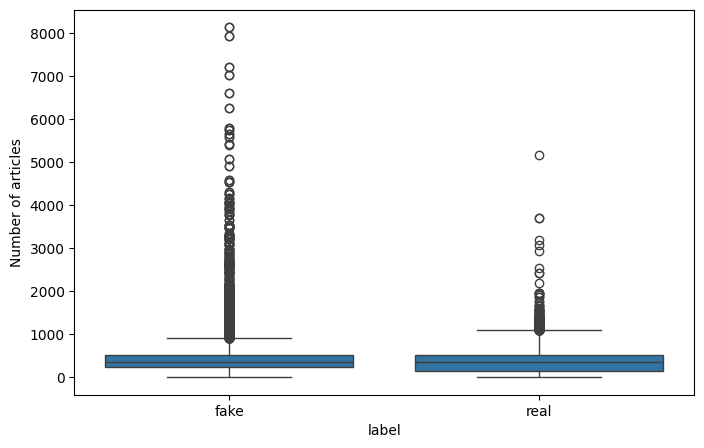

In [37]:
# Plot to show the variation in word in fake vs real

plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x='label',
    y='word_count'
)

plt.xticks(
    [0,1] , ['fake', 'real']
)
plt.ylabel('Number of articles')
plt.show()

 The above plot shows a significant difference in length of texts in fake vs rwal articles/news.This shows that fake news have generally larger text length.

In [38]:
# Title length
df['title_wc']=df['title'].str.split().str.len()

In [39]:
df['title_wc'].describe()

count    44685.000000
mean        12.463422
std          4.116303
min          1.000000
25%         10.000000
50%         11.000000
75%         14.000000
max         42.000000
Name: title_wc, dtype: float64

In [40]:
df.duplicated().sum()


np.int64(0)

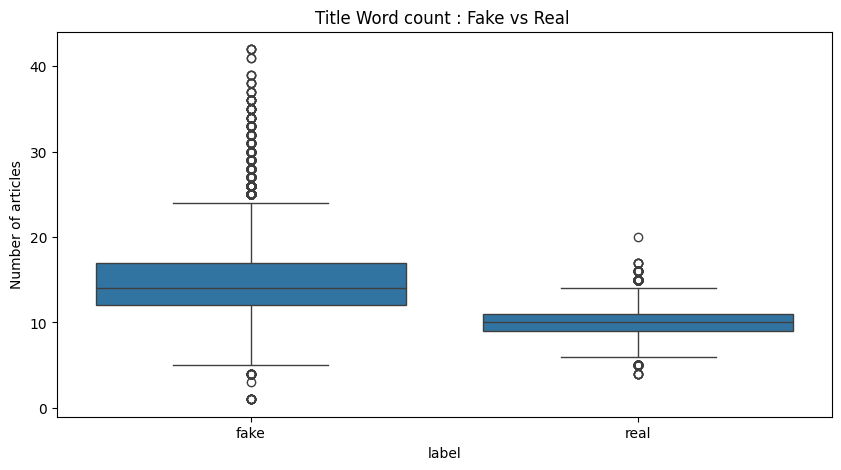

In [41]:
# Plot to show the variation in title length in fake vs real

plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='label',
    y='title_wc'
)

plt.xticks(
    [0,1] , ['fake', 'real']
)
plt.title("Title Word count : Fake vs Real ")
plt.ylabel('Number of articles')
plt.show()

In [42]:
df.columns

Index(['title', 'text', 'subject', 'label', 'word_count', 'title_wc'], dtype='object')

In [43]:
# df.drop([ 'word_count', 'title_wc', 'subject'], axis=1, inplace=True)

In [44]:
df[['title','text', 'label']].sample(10 , random_state=1)

,title,text,label
11086,DIAMOND AND SILK Open Up LARGE Can Of WHOOP A$...,OMG. Why do these two gems of social media not...,0
13215,FEDERAL JUDGE Goes On Rant About Cops Killing ...,This is a great story for anyone who doesn t u...,0
196,Trump SCREAMS On Twitter After Seeing A Poll ...,Rex Tillerson was right. Donald Trump is a f*c...,0
18630,5 BIG LIES THE LEFTY MEDIA TOLD THIS WEEK…Then...,We have very few favorites when it comes to re...,0
3310,History Channel Classification Of The 2016 El...,The History channel has spoken and Donald Trum...,0
26724,Bernie Sanders urges progressives to seek more...,CHICAGO (Reuters) - Buoyed by the British Labo...,1
6405,Gun Dealer Backs Out Of Selling Zimmerman’s M...,"George Zimmerman, the infamous neighborhood wa...",0
43285,"China urges peaceful, diplomatic resolution to...",BEIJING (Reuters) - China s Foreign Ministry s...,1
11163,TUCKER CARLSON Shocked At Lawyer’s Delusion On...,A Texas federal judge appointed by Obama has a...,0
26635,"U.S. Senate votes near unanimously for Russia,...",WASHINGTON (Reuters) - The U.S. Senate voted n...,1


In [45]:
df['label'].dtype

dtype('int64')

# Cleaning data

In [46]:
df['title']=df['title'].str.lower()
df['text']=df['text'].str.lower()

In [47]:
# Removing extra whitespace
df["title"] = df["title"].str.replace(r"\s+", " ", regex=True).str.strip()

df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()

In [48]:
# Combine title and text into one feature "content"

df['content']= df['title'] + " " + df['text']

In [49]:
df.sample(10,random_state=5)

,title,text,subject,label,word_count,title_wc,content
12296,"dc imam: “zionists brought trump, like hitler,...",a dc imam was caught on camera spewing hatred ...,politics,0,184,17,"dc imam: “zionists brought trump, like hitler,..."
1058,texas republican bringing two anti-lgbt bathro...,"representative ron simmons, r-carrollton, is b...",News,0,434,14,texas republican bringing two anti-lgbt bathro...
36894,turkey to do whatever necessary if banking sec...,istanbul (reuters) - deputy prime minister meh...,worldnews,1,64,13,turkey to do whatever necessary if banking sec...
15476,how failed democrat leadership is taking nyc b...,miss him yet?here s an up-close look at a qual...,politics,0,465,12,how failed democrat leadership is taking nyc b...
34668,bid to mine more coal on u.s. federal lands te...,washington (reuters) - president barack obama’...,politicsNews,1,534,13,bid to mine more coal on u.s. federal lands te...
23978,trump to make remarks at white house at 3 p.m....,washington (reuters) - u.s. president donald t...,politicsNews,1,30,11,trump to make remarks at white house at 3 p.m....
17542,just in: “pit bull” attorney for special couns...,is there a single person left on robert muelle...,left-news,0,215,15,just in: “pit bull” attorney for special couns...
40231,ending iran nuclear deal would worsen north ko...,geneva (reuters) - u.s. president donald trump...,worldnews,1,473,10,ending iran nuclear deal would worsen north ko...
3742,donald trump gets humiliated in the most epic ...,"this is perfect.for months, donald trump has b...",News,0,360,14,donald trump gets humiliated in the most epic ...
8420,"trump: if i’m elected, i’ll appoint justices w...",the nightmare that is donald trump just keeps ...,News,0,790,12,"trump: if i’m elected, i’ll appoint justices w..."


In [50]:
data=df.copy()

In [51]:
data.drop(columns=['title','text','subject','word_count','title_wc'], inplace=True)

# Dropping duplicated values from cleaned dataset

In [52]:
data.duplicated().sum()

np.int64(5585)

In [53]:
data.groupby("content")["label"].nunique().value_counts()

label
1    39100
Name: count, dtype: int64

In [54]:
import re

def remove_source_markers(text):
    text = re.sub(
        r'\bWASHINGTON\s*\(\s*REUTERS\s*\)\s*[-:]?',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r'\bSOURCES?\s*:\s*REUTERS\b',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(
        r'\bREUTERS\b',
        ' ',
        text,
        flags=re.IGNORECASE
    )

    text = re.sub(r'\s+', ' ', text).strip()

    return text

In [55]:
data["content"] = data["content"].apply(
    remove_source_markers
)

In [56]:
data["content"].str.contains(
    r'\breuters\b',
    case=False,
    regex=True,
    na=False
).sum()

np.int64(0)

In [57]:
data = df.copy()

print("Shape:", data.shape)
print("Full-row duplicates:", data.duplicated().sum())

print(
    "Duplicate articles:",
    data.duplicated(subset=["content"]).sum()
)

print(
    "Duplicate title + text:",
    data.duplicated(subset=["title", "text"]).sum()
)

Shape: (44685, 7)
Full-row duplicates: 5
Duplicate articles: 5585
Duplicate title + text: 5585


In [58]:
data = data.drop_duplicates(
    subset=["content"]
).reset_index(drop=True)

In [59]:
print("New shape:", data.shape)
print("Duplicate articles:", data.duplicated(subset=["content"]).sum())

New shape: (39100, 7)
Duplicate articles: 0


In [60]:
data["label"].value_counts()

label
1    21195
0    17905
Name: count, dtype: int64

In [61]:
data["label"].value_counts(normalize=True) * 100

label
1    54.207161
0    45.792839
Name: proportion, dtype: float64

In [62]:
data = data.drop_duplicates(
    subset="content",
    keep="first"
).reset_index(drop=True)

print(data.shape)
print(data.duplicated(subset="content").sum())

(39100, 7)
0


# Train Test Validation split

In [63]:
x=data['content']
y=data['label']

In [64]:
x_train , x_test , y_train , y_test = train_test_split(x,y, test_size=0.25 , random_state=2, stratify=y)

# Stratify=y is used because we want our training and test sets to have approximately the same proportion.

# stratify=y helps maintain that class distribution.

In [65]:
# validation split
x_train ,  x_val ,y_train, y_val = train_test_split(x_train , y_train  , test_size=0.1 , stratify= y_train, random_state=22)


In [66]:
print('Length of x_train', len(x_train))
print('Length of x_val', len(x_val))
print('Length of x_test', len(x_test))

Length of x_train 26392
Length of x_val 2933
Length of x_test 9775


# Tokenization

In [67]:
tokenizer= Tokenizer (
    num_words=30000,
    oov_token="<OOV>"
)

In [68]:
tokenizer.fit_on_texts(x_train)

In [69]:
# Number of unique tokens 
len(tokenizer.word_index)

119508

In [70]:
# text to sequence
x_train_seq = tokenizer.texts_to_sequences(x_train)
x_val_seq=tokenizer.texts_to_sequences(x_val)
x_test_seq = tokenizer.texts_to_sequences(x_test)

In [71]:
#Padding
max_len=750


In [72]:
x_train_pad= pad_sequences(
    x_train_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
    
)

x_test_pad= pad_sequences(
    x_test_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
    
)

x_val_pad= pad_sequences(
    x_val_seq,
    maxlen=max_len,
    padding='post',
    truncating='post'
    
)

In [73]:
y_train = np.array(y_train)
y_test = np.array(y_test)
y_val=np.array(y_val)

In [74]:
print("X_train:", x_train_pad.shape)
print("X_test:", x_test_pad.shape)
print("X_val:", x_val_pad.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print("y_val:", y_val.shape)

X_train: (26392, 750)
X_test: (9775, 750)
X_val: (2933, 750)
y_train: (26392,)
y_test: (9775,)
y_val: (2933,)


In [75]:
print(x_train_pad[0])

[28001  4001  2086  8397    22  2230  2065   601  6370    60  4001  5602
   429   197  8397 13573    22  2230     2   111   664     4     5  4151
    93    55     7     5 10136  1400   911    21     2  8877     8 14217
    55   601   511     3     2 13573   311    13    10   208  8397   855
   672   311    22  3307  5602   703    11    48    79   565   118   688
     3   252    65    27   126    11  4002     7     5   244  7415    10
     2  3500   316  1902  3584 13786    21     5  2641  7245  3065    11
  4223 17667     7   588  8397    41  1624    65     3   322   118     7
  1122    57   398  1590    55   107  2369   197    18  3240     7     5
  1001   244    11  3786   118    10   208    54    22  2313   253  3590
    13    53   519    30    12    66     5   414     4    55 26553  5602
   102     2   601   115    24   125   154    54    41  1441  8397     9
  2216 10241 13573    30  1968     2   134  9777    18 17667     7     5
  2962  1927     6  2230    91  6466     3  3850   

In [76]:
print(y_train[0])

1


In [77]:
print("Total zeros:", (x_train_pad == 0).sum())
print(
    "Sequences containing padding:",
    ((x_train_pad == 0).sum(axis=1) > 0).sum()
)
print(
    "Sequences with no padding:",
    ((x_train_pad == 0).sum(axis=1) == 0).sum()
)

Total zeros: 9502628
Sequences containing padding: 23658
Sequences with no padding: 2734


In [78]:
lengths = np.array([len(seq) for seq in x_train_seq])

print("Average:", lengths.mean())
print("Median:", np.median(lengths))
print("95th percentile:", np.percentile(lengths, 95))
print("Articles > 500:", (lengths > 500).sum())
print("Percentage > 500:", (lengths > 500).mean() * 100)

Average: 420.7802743255532
Median: 387.0
95th percentile: 914.0
Articles > 500: 7642
Percentage > 500: 28.955744164898455


In [79]:
vocab_size = min(
    50000,
    len(tokenizer.word_index) + 1
)

print("Vocabulary size:", vocab_size)

Vocabulary size: 50000


# Model Training

In [80]:
EMBED_DIM=128

model= Sequential(
    [
        Embedding(
            input_dim= vocab_size,
            output_dim=EMBED_DIM,
            mask_zero=True
        ),

        Bidirectional(
            LSTM(64)
        ),

        Dense(64 , activation='relu'),
        Dropout(0.5),
        Dense(1 , activation='sigmoid')

    ]
)

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

#since input_length is deprecated so we need to include the below line instead before compiling
model.build(input_shape=(None, max_len))

model.summary()

I0000 00:00:1787851112.454827      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1787851112.457773      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 750, 128)       │     6,400,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,507,137 (24.82 MB)

 Trainable params: 6,507,137 (24.82 MB)

 Non-trainable params: 0 (0.00 B)

In [81]:
early_stop= EarlyStopping (
    monitor='val_loss',
    patience =3,
    restore_best_weights=True
)

reduce_lr=ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=1,
    min_lr= 1e-6
)

checkpoint = ModelCheckpoint(
    'best_bilstm.keras',
    monitor='val_loss',
    save_best_only= True
)

In [82]:
history= model.fit(
    x_train_pad,
    y_train,
    validation_data= (x_val_pad , y_val),
    epochs=15,
    batch_size=64,
    callbacks=[
        early_stop,
        reduce_lr, 
        checkpoint
    ],
    verbose=1
)

Epoch 1/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 29s 56ms/step - accuracy: 0.9782 - loss: 0.0589 - val_accuracy: 0.9983 - val_loss: 0.0070 - learning_rate: 0.0010
Epoch 2/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 22s 53ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9990 - val_loss: 0.0039 - learning_rate: 0.0010
Epoch 3/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - accuracy: 0.9999 - loss: 3.1237e-04 - val_accuracy: 0.9986 - val_loss: 0.0054 - learning_rate: 0.0010
Epoch 4/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 21s 51ms/step - accuracy: 1.0000 - loss: 6.1900e-05 - val_accuracy: 0.9986 - val_loss: 0.0058 - learning_rate: 5.0000e-04
Epoch 5/15
413/413 ━━━━━━━━━━━━━━━━━━━━ 22s 53ms/step - accuracy: 1.0000 - loss: 3.7639e-05 - val_accuracy: 0.9986 - val_loss: 0.0061 - learning_rate: 2.5000e-04


In [83]:
df.head()

,title,text,subject,label,word_count,title_wc,content
0,donald trump sends out embarrassing new year’s...,donald trump just couldn t wish all americans ...,News,0,495,12,donald trump sends out embarrassing new year’s...
1,drunk bragging trump staffer started russian c...,house intelligence committee chairman devin nu...,News,0,305,8,drunk bragging trump staffer started russian c...
2,sheriff david clarke becomes an internet joke ...,"on friday, it was revealed that former milwauk...",News,0,580,15,sheriff david clarke becomes an internet joke ...
3,trump is so obsessed he even has obama’s name ...,"on christmas day, donald trump announced that ...",News,0,444,14,trump is so obsessed he even has obama’s name ...
4,pope francis just called out donald trump duri...,pope francis used his annual christmas day mes...,News,0,420,11,pope francis just called out donald trump duri...


In [98]:
for i in range(10):

    probability = pred_probs[i][0]
    prediction = int(probability >= 0.5)

    print("=" * 80)
    print("ARTICLE:")
    print(x_test.iloc[i][:500])

    print("\nActual label:", y_test[i])
    print("Predicted label:", prediction)
    print("Probability real:", round(probability, 4))

ARTICLE:
christian gun nut shoots unarmed man dead during church service and gets away with it (video) .during the days of the old west shooting an an unarmed man violated a code that cowboys lived by and brought shame as well as arrest and prosecution for murder.but in the conservative version of the old west we are being forced to live in today, codes and the law mean nothing as long as you re a christian gun nut.during the morning church service on sunday at keystone fellowship church located within m

Actual label: 0
Predicted label: 0
Probability real: 0.0
ARTICLE:
doj leader puts blame for riots on…slavery? it s no accident that president obama named vanita gupta acting head of the civil rights division of the doj. gupta is beloved by the radical left for her militant hostility toward law enforcement officers. here s a fantastic overview from j. christian adams who has intimate knowledge of what s going on at the doj. he worked there and knows just how the doj has been turned int

In [92]:
sample_news = """
The government announced today that the central bank will maintain
interest rates at their current level following its latest policy meeting.
Officials said inflation has continued to moderate, while economic
growth remains stable.
"""

test_real = """
The company reported higher quarterly revenue on Thursday,
citing stronger demand for its products in international markets.
Executives said the company expects continued growth during the
second half of the year.
"""

test_fake = """
SHOCKING!!! Scientists have finally confirmed that drinking
three cups of coffee every morning will make humans live forever.
The government has secretly known about this discovery for years
but refused to tell the public.
"""

sequence = tokenizer.texts_to_sequences([test_real])

padded = pad_sequences(
    sequence,
    maxlen=750,
    padding="post",
    truncating="post"
)

probability = model.predict(padded, verbose=0)[0][0]

print("Probability of label 1:", probability)

Probability of label 1: 0.88187873


# Evaluate the model

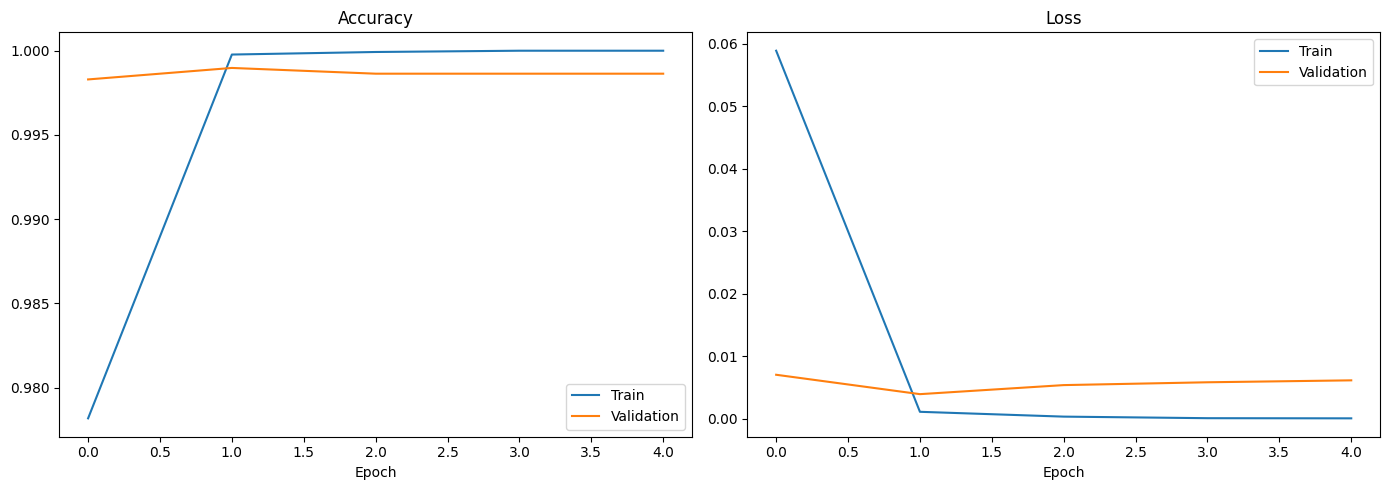

In [99]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history.history['accuracy'], label='Train')
axes[0].plot(history.history['val_accuracy'], label='Validation')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Train')
axes[1].plot(history.history['val_loss'], label='Validation')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()

plt.tight_layout()
plt.show()

Test Accuracy: 0.9993
Test Loss:     0.0020
306/306 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step

              precision    recall  f1-score   support

     Class 0       1.00      1.00      1.00      4476
     Class 1       1.00      1.00      1.00      5299

    accuracy                           1.00      9775
   macro avg       1.00      1.00      1.00      9775
weighted avg       1.00      1.00      1.00      9775



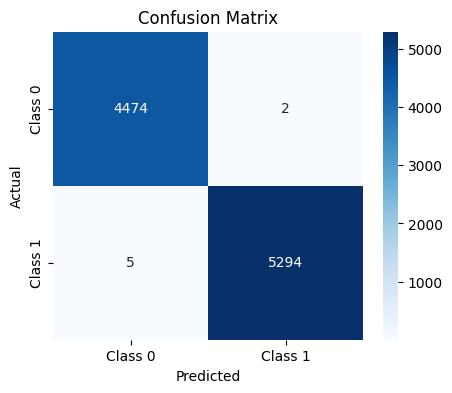

In [102]:
test_loss, test_acc = model.evaluate(x_test_pad, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss:     {test_loss:.4f}")

y_pred_prob = model.predict(x_test_pad)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print()
print(classification_report(y_test, y_pred, target_names=['Class 0', 'Class 1']))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1'], yticklabels=['Class 0', 'Class 1'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [108]:
vocab_size=30000
model.save('/kaggle/working/ISOT_model_27aug.keras')

with open('/kaggle/working/tokenizer.pickle', 'wb') as f:
    pickle.dump(tokenizer, f, protocol=pickle.HIGHEST_PROTOCOL)

with open('/kaggle/working/model_config.json', 'w') as f:
    json.dump({'MAX_LEN': max_len, 'VOCAB_SIZE': vocab_size}, f)

print("Saved model, tokenizer, and config to /kaggle/working/")

Saved model, tokenizer, and config to /kaggle/working/
